https://www.sbmo.org.br/anais_momag/momag2012/artigos/100744_1.pdf - artigo métricas de robustez

# Conectividade da malha aérea doméstica brasileira (VRA - ANAC)

Reproduz a execução da `main` de `analise_malha.py`, usando as funções de `funcoes_malha.py`.

In [1]:
import itertools
import os

import networkx as nx
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd

from funcoes_malha import *

## Parâmetros
Equivalem aos argumentos de linha de comando do script.

In [2]:
PASTA = "dados"      # --pasta
SAIDA = "saida"      # --saida
TIPOS = ["N"]        # --tipos  (ex.: ["N", "C"] inclui cargueiros nacionais)
HUBS = None          # --hubs   (ex.: 60 limita os pares aos 60 maiores)
TOP = 15             # --top

os.makedirs(SAIDA, exist_ok=True)

## Leitura e filtro dos voos domésticos

In [3]:
print("Lendo CSVs:")
voos = carrega_voos(PASTA)
dom = filtra_domesticos(voos, TIPOS)

Lendo CSVs:
  VRA_20251.csv: 89616 linhas
  VRA_202510.csv: 85709 linhas
  VRA_202511.csv: 82245 linhas
  VRA_202512.csv: 88564 linhas
  VRA_20252.csv: 78930 linhas
  VRA_20253.csv: 82048 linhas
  VRA_20254.csv: 80692 linhas


c:\Users\Gabriel Che\Documents\Fluxos\funcoes_malha.py:83: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  "partida_real": pd.to_datetime(df[acha_coluna(df, "partida", "real")],


  VRA_20255.csv: 82565 linhas
  VRA_20256.csv: 80974 linhas
  VRA_20257.csv: 87725 linhas
  VRA_20258.csv: 84583 linhas
  VRA_20259.csv: 82156 linhas

Etapas entre aeródromos brasileiros, por 'Código Tipo Linha':
tipo_linha
N     801166
C      15189
G       1948
I        977
NA       243

Situação Voo: {'REALIZADO': 978091, 'CANCELADO': 27716}

Tipos usados: ['N'] -> 1005807 etapas no arquivo, 801166 domésticas (787099 realizadas)


## Grafo da malha
Só etapas realizadas viram arestas; a análise segue na maior componente.

In [4]:
G_total = monta_grafo(dom[dom["situacao"] == "REALIZADO"])

comps = sorted(nx.connected_components(G_total), key=len, reverse=True)
print(f"Grafo: {G_total.number_of_nodes()} aeroportos, {G_total.number_of_edges()} rotas, "
      f"{len(comps)} componente(s)")
if len(comps) > 1:
    print("  Componentes menores (fora da rede principal):",
          [sorted(c) for c in comps[1:]])

G = G_total.subgraph(comps[0]).copy()  # análise na maior componente

Grafo: 176 aeroportos, 964 rotas, 1 componente(s)


### Grafo total

Arquivo interativo HTML - pyvis

In [5]:
import numpy as np
from pyvis.network import Network

H = G_total.copy()
pos = nx.spring_layout(H, k=1.5 / np.sqrt(H.number_of_nodes()), iterations=200, seed=42)

ESCALA = 1000   # o spring_layout devolve coordenadas em [-1, 1]; a pyvis trabalha em pixels
for v, (x, y) in pos.items():
    H.nodes[v]["x"] = float(x * ESCALA)
    H.nodes[v]["y"] = float(-y * ESCALA)   # no canvas o eixo y cresce para baixo

net = Network(notebook=True, cdn_resources="in_line", height="750px", width="100%")
net.from_nx(H)
net.toggle_physics(False)

arquivo = "grafo_interativo.html"
with open(arquivo, "w", encoding="utf-8") as f:
    f.write(net.generate_html(notebook=True))

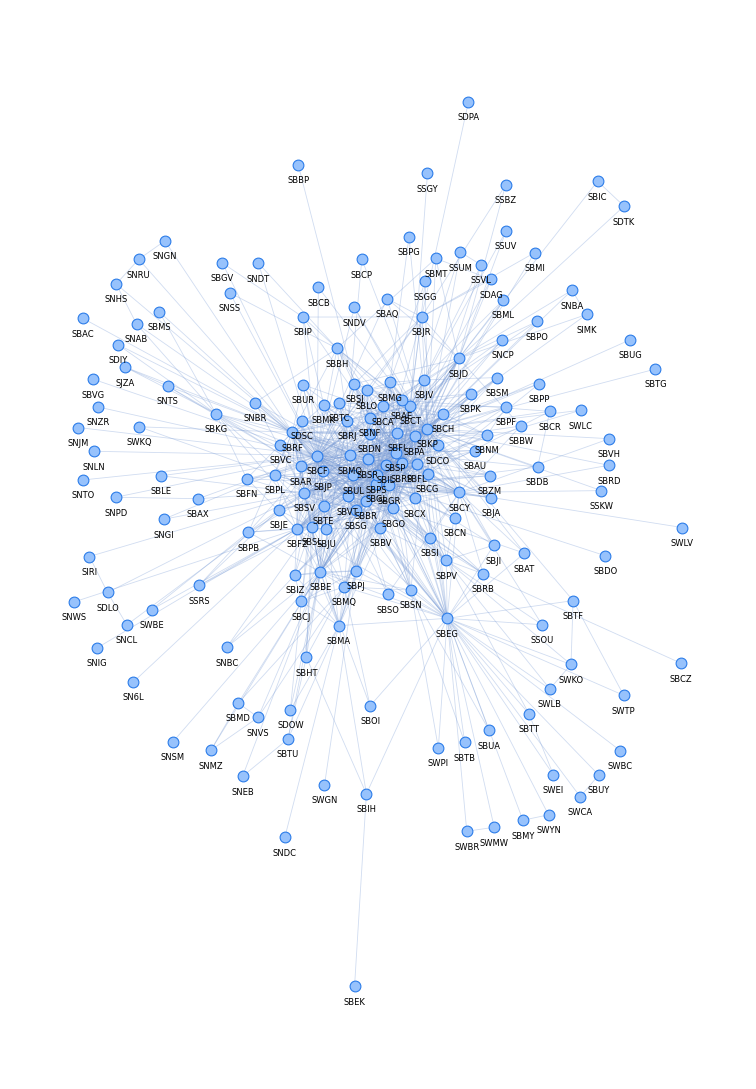

In [6]:
fig, ax = plt.subplots(figsize=(14, 11))
nx.draw_networkx_edges(H, pos, width=0.6, alpha=0.35, edge_color="#7a9cd6", ax=ax)
nx.draw_networkx_nodes(H, pos, node_size=60, node_color="#97c2fc",
                       edgecolors="#2b7ce9", linewidths=0.8, ax=ax)
nx.draw_networkx_labels(H, pos, font_size=6, ax=ax,
                        verticalalignment="top",
                        labels={v: f"\n{v}" for v in H.nodes})   # rótulo abaixo do nó, como na pyvis
ax.set_aspect("equal")
ax.axis("off")
plt.tight_layout()

plt.savefig("grafo_interativo.png", dpi=200, bbox_inches="tight")
plt.show()

In [7]:
import numpy as np
from pyvis.network import Network

H = G_total.copy()
n = H.number_of_nodes()

# 1) Mais repulsão entre os nós: k maior = distância "ideal" maior entre vértices
pos = nx.spring_layout(H, k=4 / np.sqrt(n), iterations=500, seed=42)

# 2) Expansão radial: afasta o miolo e quase não mexe na periferia.
#    Cada ponto mantém a direção em relação ao centro; o raio r vira r**ALFA.
#    ALFA = 1 não muda nada; quanto menor, mais o centro se abre.
ALFA = 0.5
centro = np.mean(list(pos.values()), axis=0)
for v, p in pos.items():
    d = p - centro
    r = np.linalg.norm(d)
    if r > 0:
        pos[v] = centro + d * r ** (ALFA - 1)

# 3) Escala maior: na pyvis o tamanho do nó é fixo, então coordenadas maiores = mais espaço entre eles
ESCALA = 2500
for v, (x, y) in pos.items():
    H.nodes[v]["x"] = float(x * ESCALA)
    H.nodes[v]["y"] = float(-y * ESCALA)
    H.nodes[v]["size"] = 8

net = Network(notebook=True, cdn_resources="in_line", height="750px", width="100%")
net.from_nx(H)
net.toggle_physics(False)

arquivo = "grafo_interativo_espacado.html"
with open(arquivo, "w", encoding="utf-8") as f:
    f.write(net.generate_html(notebook=True))

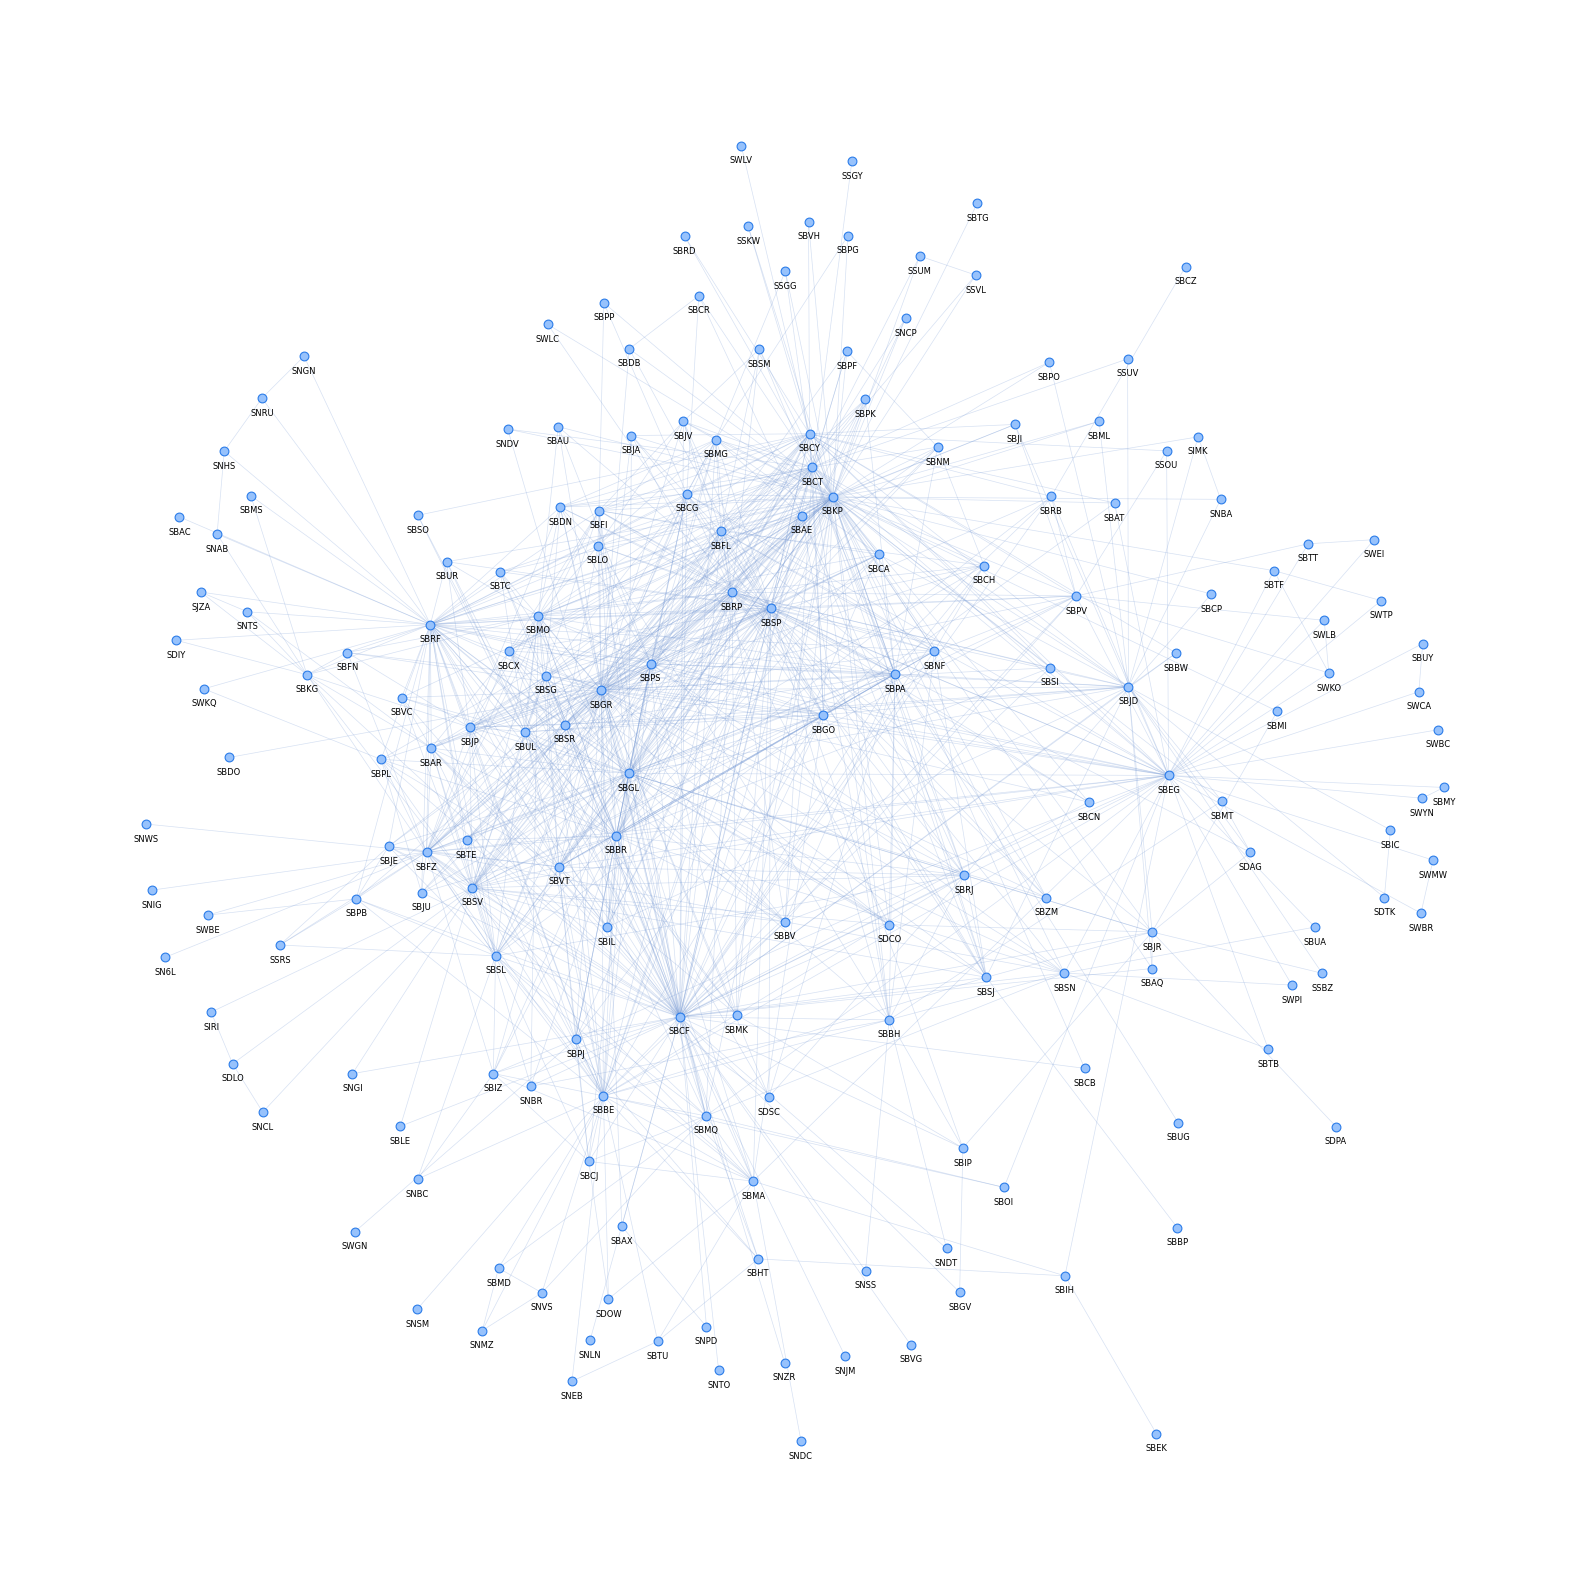

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(16, 16))
nx.draw_networkx_edges(H, pos, width=0.5, alpha=0.3, edge_color="#7a9cd6", ax=ax)
nx.draw_networkx_nodes(H, pos, node_size=40, node_color="#97c2fc",
                       edgecolors="#2b7ce9", linewidths=0.8, ax=ax)
nx.draw_networkx_labels(H, pos, font_size=6, ax=ax,
                        verticalalignment="top",
                        labels={v: f"\n{v}" for v in H.nodes})   # rótulo abaixo do nó
ax.set_aspect("equal")
ax.axis("off")
plt.tight_layout()

plt.savefig("grafo_interativo_espacado.png", dpi=200, bbox_inches="tight")
plt.show()

Visualização interativa - Plotly

Maior detalhamento de vértices, conexões e quantidade de voos

In [9]:
import numpy as np
import plotly.graph_objects as go

grafo = G_total
N_ROTULOS = 20

pos = nx.spring_layout(grafo, k=1.5 / np.sqrt(grafo.number_of_nodes()), iterations=200, seed=42)
graus = dict(grafo.degree())
articulacao = set(nx.articulation_points(grafo))
hubs = set(sorted(grafo.nodes, key=graus.get, reverse=True)[:N_ROTULOS])

# --- rotas: o Plotly aceita uma espessura por traço, então agrupo em faixas de nº de voos
arestas = list(grafo.edges(data="voos"))
voos = np.array([v for *_, v in arestas])
cortes = np.quantile(voos, [0.5, 0.8, 0.95])          # 4 faixas: até mediana, ..., top 5%
faixa = np.digitize(voos, cortes)
larguras = [0.4, 1.0, 2.0, 4.0]

tracos = []
for i, w in enumerate(larguras):
    x, y = [], []
    for (a, b, _), f in zip(arestas, faixa):
        if f == i:
            x += [pos[a][0], pos[b][0], None]
            y += [pos[a][1], pos[b][1], None]
    tracos.append(go.Scatter(x=x, y=y, mode="lines", hoverinfo="skip", showlegend=False,
                             line=dict(width=w, color="rgba(120,120,120,0.35)")))

# pontos invisíveis no meio de cada rota, só para o hover mostrar o nº de voos
tracos.append(go.Scatter(
    x=[(pos[a][0] + pos[b][0]) / 2 for a, b, _ in arestas],
    y=[(pos[a][1] + pos[b][1]) / 2 for a, b, _ in arestas],
    mode="markers", marker=dict(size=6, opacity=0), showlegend=False,
    hovertext=[f"{a} – {b}: {v} voos" for a, b, v in arestas], hoverinfo="text"))

# --- aeroportos: um traço para os comuns e outro para os pontos de articulação
def traco_nos(nos, cor, nome):
    return go.Scatter(
        x=[pos[v][0] for v in nos], y=[pos[v][1] for v in nos],
        mode="markers+text", name=nome,
        text=[v if v in hubs else "" for v in nos], textposition="top center",
        textfont=dict(size=9),
        marker=dict(size=[6 + 1.2 * graus[v] for v in nos], color=cor,
                    line=dict(width=0.5, color="white")),
        hovertext=[f"{v}<br>grau: {graus[v]}" for v in nos], hoverinfo="text")

comuns = [v for v in grafo.nodes if v not in articulacao]
tracos.append(traco_nos(comuns, "steelblue", "aeroporto"))
tracos.append(traco_nos(sorted(articulacao), "crimson", "ponto de articulação"))

fig = go.Figure(tracos)
fig.update_layout(
    title=f"Malha aérea doméstica — {grafo.number_of_nodes()} aeroportos, "
          f"{grafo.number_of_edges()} rotas (tamanho = grau, espessura = nº de voos)",
    height=800, plot_bgcolor="white", hovermode="closest",
    xaxis=dict(visible=False), yaxis=dict(visible=False, scaleanchor="x"),
    legend=dict(x=0, y=0))
fig.show()

fig.write_html(os.path.join(SAIDA, "grafo_plotly.html"))   # grava em UTF-8, abre no navegador

## Conectividade global (Whitney: κ ≤ λ ≤ δ)

In [10]:
graus = [d for _, d in G.degree()]
print(f"κ(G) = {nx.node_connectivity(G)}   λ(G) = {nx.edge_connectivity(G)}   "
      f"δ(G) = {min(graus)}   (Whitney: κ ≤ λ ≤ δ)")
print("Pontos de articulação:", sorted(nx.articulation_points(G)))

κ(G) = 1   λ(G) = 1   δ(G) = 1   (Whitney: κ ≤ λ ≤ δ)
Pontos de articulação: ['SBBE', 'SBCF', 'SBCT', 'SBCY', 'SBEG', 'SBFZ', 'SBGR', 'SBIH', 'SBJD', 'SBJR', 'SBKP', 'SBMA', 'SBPA', 'SBPJ', 'SBRB', 'SBRF', 'SBSJ', 'SBSV']


$\kappa(G) = \lambda(G) = \delta(G) \implies{\text{Grafo maximamente conexo}} $

De acordo com A. Hellwig e I. Volkmann, essa configuração estrutural favorece grafos tolerantes a falhas.

## Simulação de falha de cada aeroporto

In [11]:
crit = simula_falhas(G).merge(metricas_operacionais(dom), on="aeroporto", how="left")
crit.to_csv(os.path.join(SAIDA, "criticidade_aeroportos.csv"), index=False)
display(crit.head(TOP))

,aeroporto,grau,voos,pct_voos_malha,ponto_articulacao,aeroportos_isolados,pares_sem_rota,etapas_programadas,taxa_cancel_pct,n_empresas,pct_empresa_dominante,atraso_mediano_partida_min
0,SBEG,47,23740,3.02,True,7,1194,24283,2.24,11,42.7,-3.0
1,SBCF,84,111647,14.18,True,5,860,113561,1.69,7,69.6,-2.0
2,SBFZ,41,36716,4.66,True,3,519,37121,1.09,8,52.1,-3.0
3,SBSV,41,53478,6.79,True,3,516,54132,1.21,8,46.5,-4.0
4,SBJD,29,291,0.04,True,2,346,291,0.00,1,100.0,NaN
5,SBGR,68,194303,24.69,True,1,174,197436,1.59,10,60.3,4.0
6,SBKP,92,107715,13.69,True,1,174,109915,2.00,9,92.5,-1.0
7,SBRF,57,69776,8.86,True,1,174,70646,1.23,9,67.8,-3.0
8,SBPA,33,52313,6.65,True,1,174,53277,1.81,8,39.7,-4.0
9,SBCT,47,49904,6.34,True,1,174,51107,2.35,6,45.7,-5.0


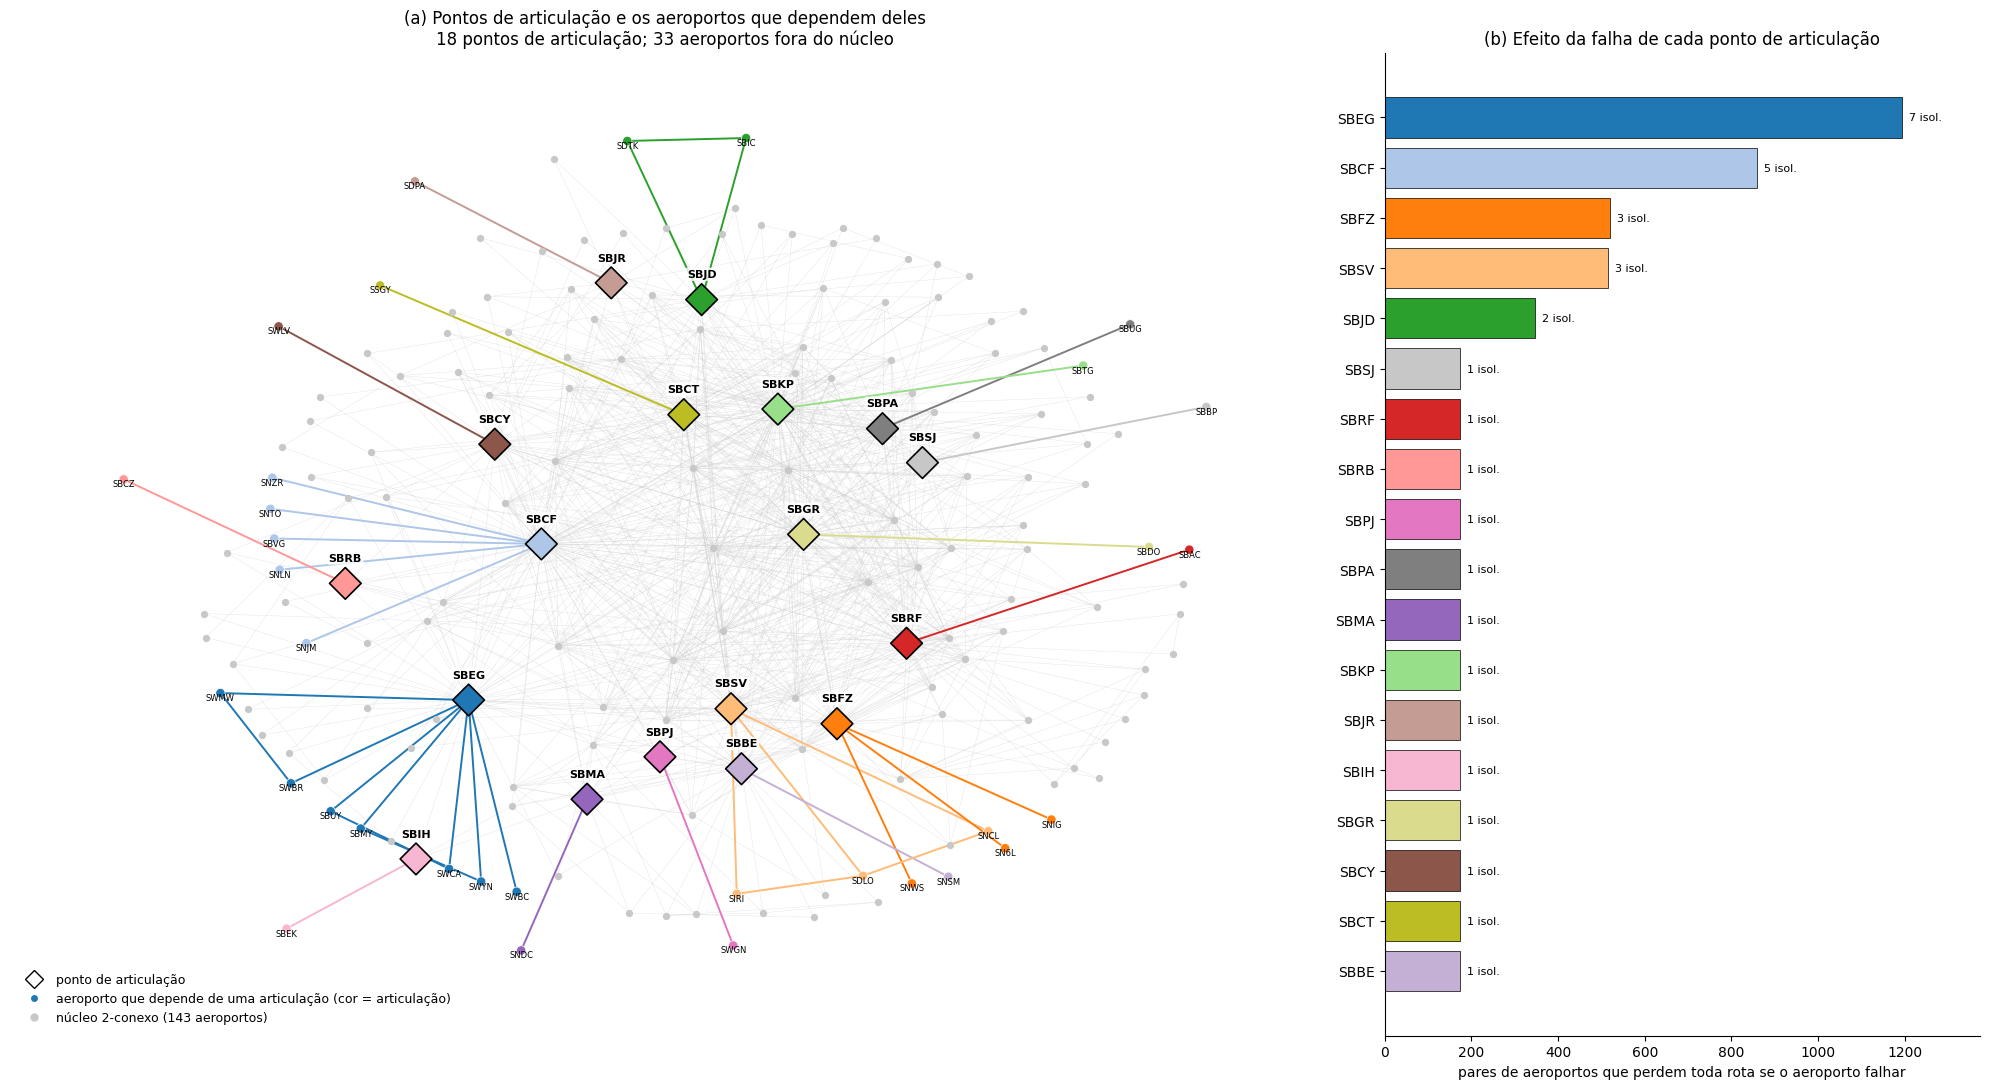

In [14]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

art = set(nx.articulation_points(G))
nucleo = max(nx.biconnected_components(G), key=len)   # maior bloco 2-conexo (núcleo da malha)

# --- efeito da falha de cada ponto de articulação
pares_perdidos, isolados = {}, {}
n = G.number_of_nodes()
for a in art:
    H = G.copy(); H.remove_node(a)
    comps = sorted(nx.connected_components(H), key=len, reverse=True)
    pares_perdidos[a] = (n - 1) * (n - 2) // 2 - sum(len(c) * (len(c) - 1) // 2 for c in comps)
    isolados[a] = (n - 1) - len(comps[0])

# --- ramos: cada aeroporto fora do núcleo depende de uma única articulação do núcleo
ramo = {}
for a in art & nucleo:
    H = G.copy(); H.remove_node(a)
    principal = max(nx.connected_components(H), key=len)
    for v in set(H) - principal:
        ramo[v] = a
raizes = sorted(art & nucleo, key=lambda a: pares_perdidos[a], reverse=True)
paleta = plt.get_cmap("tab20")
cor_raiz = {a: paleta(i % 20) for i, a in enumerate(raizes)}
cor = {v: cor_raiz[ramo[v]] for v in ramo} | cor_raiz
CINZA = "#c8c8c8"

# --- layout: Kamada-Kawai + expansão radial para abrir o núcleo
pos = nx.kamada_kawai_layout(G)
ALFA = 0.6
centro = np.mean(list(pos.values()), axis=0)
for v, p in pos.items():
    d = p - centro; r = np.linalg.norm(d)
    if r > 0:
        pos[v] = centro + d * r ** (ALFA - 1)

fig, (ax, axb) = plt.subplots(1, 2, figsize=(20, 11), gridspec_kw={"width_ratios": [2.2, 1]})

# (a) rede
arestas_nucleo = [(a, b) for a, b in G.edges if a in nucleo and b in nucleo]
arestas_ramo = [(a, b) for a, b in G.edges if not (a in nucleo and b in nucleo)]
nx.draw_networkx_edges(G, pos, edgelist=arestas_nucleo, edge_color=CINZA, width=0.3, alpha=0.5, ax=ax)
nx.draw_networkx_edges(G, pos, edgelist=arestas_ramo, width=1.4, ax=ax,
                       edge_color=[cor[a if a in ramo else b] for a, b in arestas_ramo])

comuns = [v for v in nucleo if v not in art]
perif = [v for v in ramo if v not in art]
nx.draw_networkx_nodes(G, pos, nodelist=comuns, node_size=18, node_color=CINZA, ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=perif, node_size=45, ax=ax,
                       node_color=[cor[v] for v in perif], edgecolors="white", linewidths=0.5)
nx.draw_networkx_nodes(G, pos, nodelist=sorted(art), node_size=260, node_shape="D", ax=ax,
                       node_color=[cor[v] for v in sorted(art)], edgecolors="black", linewidths=1.2)

dy = 0.025 * (max(p[1] for p in pos.values()) - min(p[1] for p in pos.values()))
pos_rot = {v: (x, y + dy) for v, (x, y) in pos.items()}   # rótulo logo acima do losango
nx.draw_networkx_labels(G, pos_rot, labels={v: v for v in art}, font_size=8, font_weight="bold",
                        verticalalignment="bottom", ax=ax,
                        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))
nx.draw_networkx_labels(G, pos, labels={v: v for v in perif}, font_size=6, ax=ax,
                        verticalalignment="top")

ax.legend(handles=[
    Line2D([], [], marker="D", ls="", ms=9, mfc="white", mec="black", label="ponto de articulação"),
    Line2D([], [], marker="o", ls="", ms=6, mfc="tab:blue", mec="white",
           label="aeroporto que depende de uma articulação (cor = articulação)"),
    Line2D([], [], marker="o", ls="", ms=5, mfc=CINZA, mec=CINZA,
           label=f"núcleo 2-conexo ({len(nucleo)} aeroportos)")],
    loc="lower left", frameon=False, fontsize=9)
ax.set_title(f"(a) Pontos de articulação e os aeroportos que dependem deles\n"
             f"{len(art)} pontos de articulação; {len(ramo)} aeroportos fora do núcleo",
             fontsize=12)
ax.axis("off")

# (b) efeito da falha de cada articulação
ordem = sorted(art, key=lambda a: (pares_perdidos[a], a))
axb.barh(ordem, [pares_perdidos[a] for a in ordem], color=[cor[a] for a in ordem],
         edgecolor="black", lw=0.5)
for i, a in enumerate(ordem):
    axb.text(pares_perdidos[a], i, f"  {isolados[a]} isol.", va="center", fontsize=8)
axb.set_xlabel("pares de aeroportos que perdem toda rota se o aeroporto falhar")
axb.set_title("(b) Efeito da falha de cada ponto de articulação", fontsize=12)
axb.spines[["top", "right"]].set_visible(False)
axb.set_xlim(0, max(pares_perdidos.values()) * 1.15)

plt.tight_layout()
plt.savefig("pontos_articulacao.png", dpi=200, bbox_inches="tight")
#plt.savefig("pontos_articulacao.pdf", bbox_inches="tight")   # vetorial, para o LaTeX
plt.show()

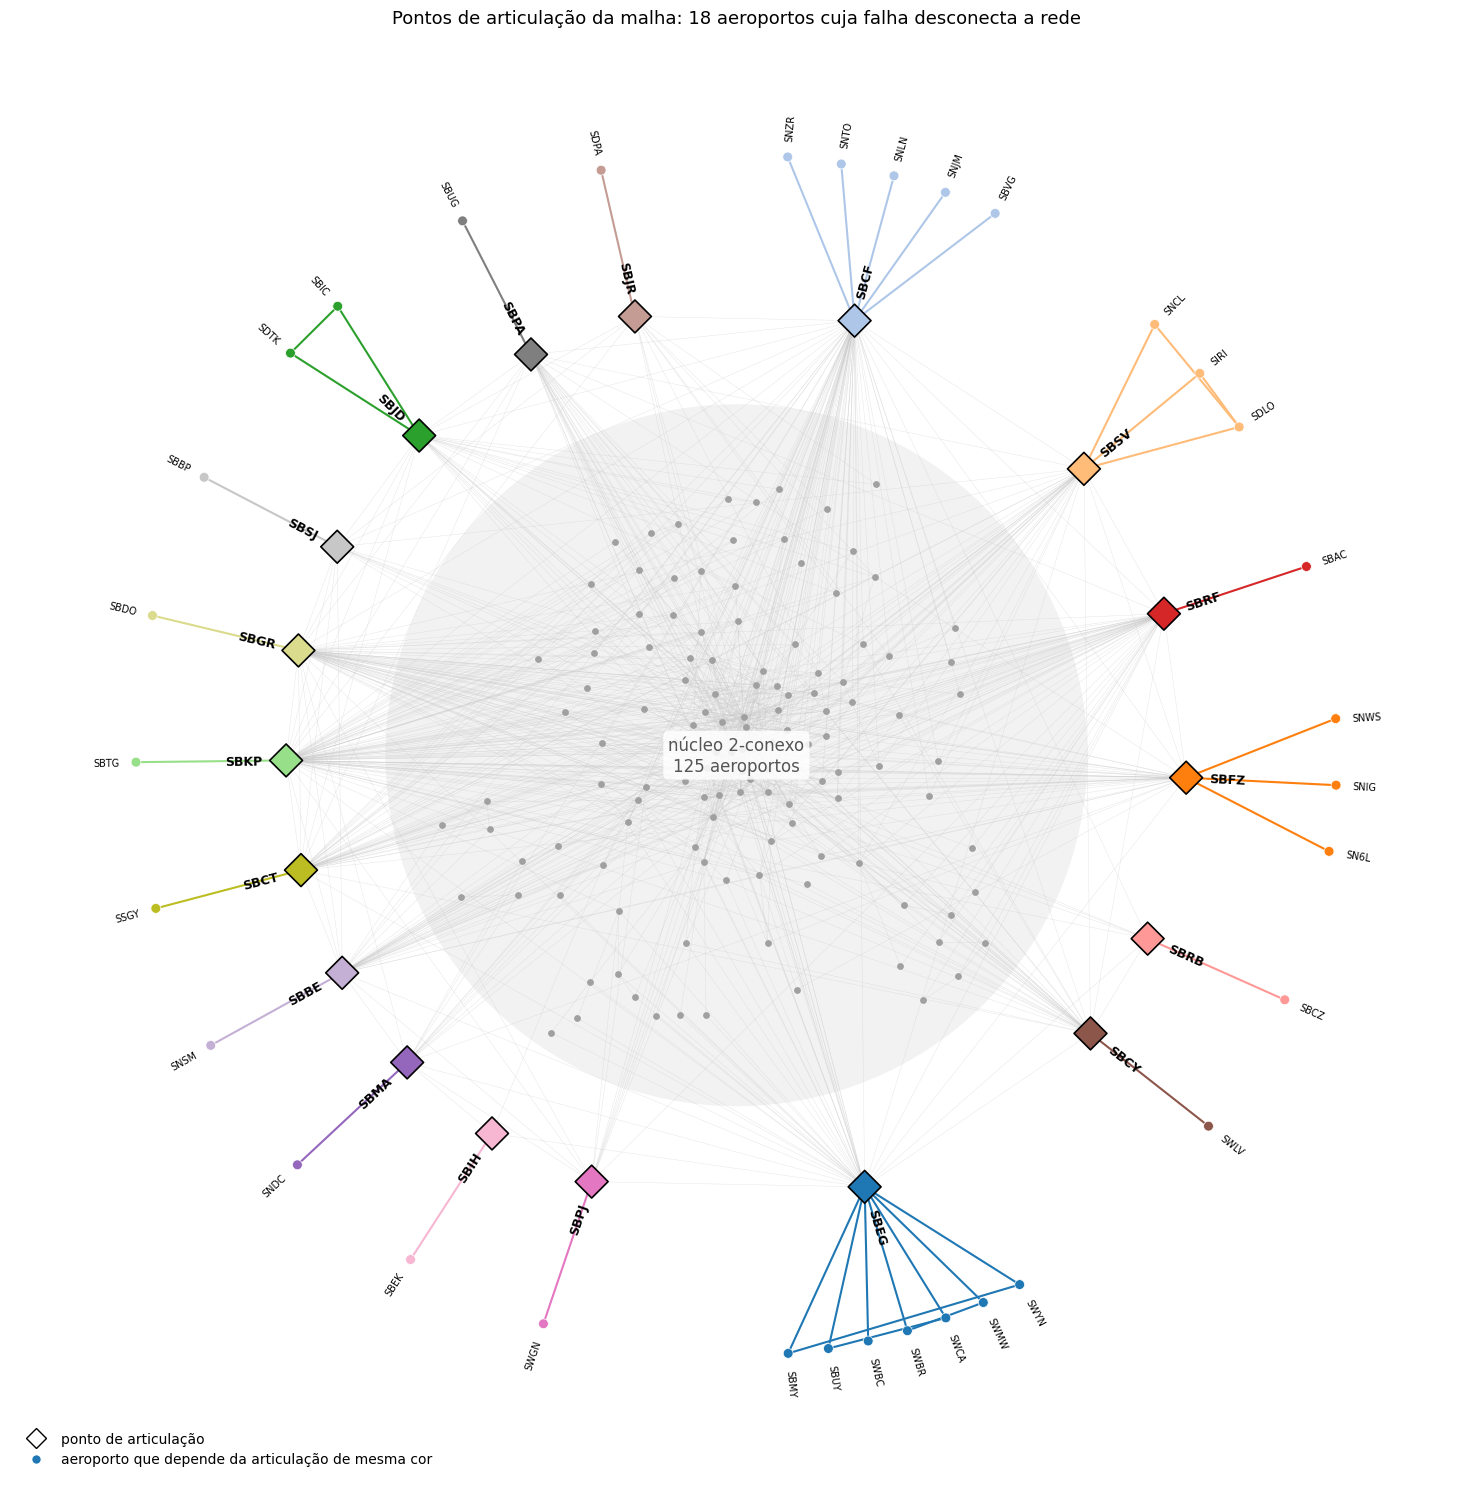

In [15]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

art = set(nx.articulation_points(G))
nucleo = max(nx.biconnected_components(G), key=len)   # maior bloco 2-conexo
raizes = art & nucleo                                  # articulações na borda do núcleo

# --- ramo de cada raiz: aeroportos que perdem a ligação com o núcleo se a raiz falhar
ramos = {}
for a in raizes:
    H = G.copy(); H.remove_node(a)
    principal = max(nx.connected_components(H), key=len)
    ramos[a] = set(H) - principal

# --- layout radial
R_NUCLEO, R_BORDA, PASSO = 1.0, 1.35, 0.45   # raio do núcleo, anel das articulações, distância entre níveis

# 1) núcleo: layout de força só entre os aeroportos do núcleo, encolhido para dentro do círculo
p_nuc = nx.spring_layout(G.subgraph(nucleo), k=2 / np.sqrt(len(nucleo)), iterations=300, seed=42)
c = np.mean(list(p_nuc.values()), axis=0)
rmax = max(np.linalg.norm(p - c) for p in p_nuc.values())
pos = {v: (p - c) / rmax * R_NUCLEO for v, p in p_nuc.items()}

# 2) articulações: no anel externo, na ordem angular em que estavam no núcleo,
#    cada uma com um setor angular proporcional ao tamanho do seu ramo
ordem = sorted(raizes, key=lambda a: np.arctan2(pos[a][1], pos[a][0]))
peso = np.array([len(ramos[a]) + 1 for a in ordem], dtype=float)
larg = 2 * np.pi * peso / peso.sum()
inicio = np.arctan2(pos[ordem[0]][1], pos[ordem[0]][0]) - larg[0] / 2 if ordem else 0
for a, w in zip(ordem, larg):
    meio = inicio + w / 2
    pos[a] = np.array([np.cos(meio), np.sin(meio)]) * R_BORDA
    # 3) ramo em leque: nível = nº de etapas a partir da articulação, dentro do ramo
    nivel = nx.single_source_shortest_path_length(G.subgraph(ramos[a] | {a}), a)
    for d in range(1, max(nivel.values(), default=0) + 1):
        camada = sorted(v for v, k in nivel.items() if k == d)
        abertura = min(w, 0.35 * d + 0.25) * 0.9            # o leque não ultrapassa o setor
        angs = meio + np.linspace(-abertura / 2, abertura / 2, len(camada) + 2)[1:-1]
        for v, t in zip(camada, angs):
            pos[v] = np.array([np.cos(t), np.sin(t)]) * (R_BORDA + d * PASSO)
    inicio += w

# --- cores: uma por ramo
paleta = plt.get_cmap("tab20")
cor = {}
for i, a in enumerate(sorted(raizes, key=lambda a: len(ramos[a]), reverse=True)):
    for v in ramos[a] | {a}:
        cor[v] = paleta(i % 20)
CINZA = "#c8c8c8"

fig, ax = plt.subplots(figsize=(15, 15))
ax.add_patch(plt.Circle((0, 0), R_NUCLEO * 1.05, color="#f2f2f2", zorder=0))

arestas_nuc = [(a, b) for a, b in G.edges if a in nucleo and b in nucleo]
arestas_ramo = [(a, b) for a, b in G.edges if not (a in nucleo and b in nucleo)]
nx.draw_networkx_edges(G, pos, edgelist=arestas_nuc, edge_color=CINZA, width=0.3, alpha=0.5, ax=ax)
nx.draw_networkx_edges(G, pos, edgelist=arestas_ramo, width=1.5, ax=ax,
                       edge_color=[cor[a] if a not in nucleo else cor[b] for a, b in arestas_ramo])

comuns = [v for v in nucleo if v not in art]
perif = [v for v in G if v not in nucleo and v not in art]
nx.draw_networkx_nodes(G, pos, nodelist=comuns, node_size=15, node_color="#a0a0a0", ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=perif, node_size=50, node_color=[cor[v] for v in perif],
                       edgecolors="white", linewidths=0.5, ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=sorted(art), node_size=280, node_shape="D",
                       node_color=[cor[v] for v in sorted(art)], edgecolors="black", linewidths=1.2, ax=ax)

# rótulos fora do círculo, alinhados na direção radial
for v in G:
    if v in nucleo and v not in art:
        continue
    x, y = pos[v]; t = np.arctan2(y, x); ang = np.degrees(t)
    direita = -90 <= ang <= 90
    off = 0.07 if v in art else 0.05
    ax.text(x + off * np.cos(t), y + off * np.sin(t), v,
            rotation=ang if direita else ang + 180, rotation_mode="anchor",
            ha="left" if direita else "right", va="center",
            fontsize=9 if v in art else 7, fontweight="bold" if v in art else "normal")

ax.text(0, 0, f"núcleo 2-conexo\n{len(nucleo) - len(raizes)} aeroportos",
        ha="center", va="center", fontsize=12, color="#555555",
        bbox=dict(boxstyle="round", fc="white", ec="none", alpha=0.85))
ax.legend(handles=[
    Line2D([], [], marker="D", ls="", ms=10, mfc="white", mec="black", label="ponto de articulação"),
    Line2D([], [], marker="o", ls="", ms=7, mfc="tab:blue", mec="white",
           label="aeroporto que depende da articulação de mesma cor")],
    loc="lower left", frameon=False, fontsize=10)
ax.set_title(f"Pontos de articulação da malha: {len(art)} aeroportos cuja falha desconecta a rede",
             fontsize=13)
ax.set_aspect("equal"); ax.axis("off")
plt.tight_layout()
plt.savefig("pontos_articulacao_radial.png", dpi=200, bbox_inches="tight")
plt.savefig("pontos_articulacao_radial.pdf", bbox_inches="tight")   # vetorial, para o LaTeX
plt.show()

## Conectividade por pares (Menger, vértices)
Só pares não adjacentes; compara κ(s,t) com o limite min(grau(s), grau(t)).

In [12]:
pares = conectividade_pares(G, HUBS)
pares.to_csv(os.path.join(SAIDA, "pares_conectividade.csv"), index=False)

print(f"{len(pares)} pares não adjacentes; "
      f"{100 * pares['atinge_limite'].mean():.1f}% atingem o limite pelo grau")
display(pares.groupby("kappa_st").size().rename("pares").to_frame())

frageis = pares.sort_values(["kappa_st", "limite_grau"]).head(TOP)

14436 pares não adjacentes; 71.1% atingem o limite pelo grau


,pares
kappa_st,
1,5207
2,4715
3,1731
4,541
5,483
6,252
7,392
8,151
9,138


## Gargalos
Corte mínimo de vértices de pares com κ(s,t) baixo e limite pelo grau alto (rede abaixo do limite).

In [13]:
abaixo = pares[~pares["atinge_limite"]].sort_values(["kappa_st", "limite_grau"],
                                                    ascending=[True, False]).head(5)
for _, r in abaixo.iterrows():
    print(f"{r['s']} - {r['t']}: κ={r['kappa_st']} (limite {r['limite_grau']}), "
          f"corte {sorted(nx.minimum_node_cut(G, r['s'], r['t']))}")

SBRJ - SDLO: κ=1 (limite 3), corte ['SBSV']
SBSP - SDLO: κ=1 (limite 3), corte ['SBSV']
SBBR - SDLO: κ=1 (limite 3), corte ['SBSV']
SBCF - SDLO: κ=1 (limite 3), corte ['SBSV']
SBPA - SDLO: κ=1 (limite 3), corte ['SBSV']


## 10 maiores Hubs

Análise de importância de vértices como intermediários através de medidas de centralidade

In [27]:
# centralidades calculadas no grafo inteiro
deg_c = nx.degree_centrality(G)        # grau / (n - 1)
clo_c = nx.closeness_centrality(G)     # 1 / (distância média, em nº de etapas, até os outros)
bet_c = nx.betweenness_centrality(G)   # fração dos caminhos mínimos que passam pelo vértice

graus = (pd.DataFrame(G.degree(), columns=["vertice", "grau"])
           .sort_values(["grau", "vertice"], ascending=False, ignore_index=True))
graus.index += 1   # ranking começando em 1

graus["degree_centrality"] = graus["vertice"].map(deg_c)
graus["closeness_centrality"] = graus["vertice"].map(clo_c)
graus["betweenness_centrality"] = graus["vertice"].map(bet_c)

# posição de cada hub no ranking de intermediação entre TODOS os aeroportos
rank_bet = pd.Series(bet_c).rank(ascending=False, method="min").astype(int)
graus["rank_betweenness"] = graus["vertice"].map(rank_bet)

display(graus.style.format({"degree_centrality": "{:.3f}",
                            "closeness_centrality": "{:.3f}",
                            "betweenness_centrality": "{:.3f}"}))

,vertice,grau,degree_centrality,closeness_centrality,betweenness_centrality,rank_betweenness
1,SBKP,92,0.526,0.670,0.223,1
2,SBCF,84,0.480,0.655,0.198,2
3,SBGR,68,0.389,0.616,0.065,6
4,SBSP,59,0.337,0.593,0.045,10
5,SBRF,57,0.326,0.581,0.114,4
6,SBGL,55,0.314,0.587,0.026,13
7,SBBR,48,0.274,0.568,0.018,18
8,SBEG,47,0.269,0.566,0.173,3
9,SBCT,47,0.269,0.568,0.048,9
10,SBRP,46,0.263,0.568,0.021,15


Vértices por grau

In [20]:
graus.sort_values(["grau", "vertice"], ascending=False, ignore_index=True).head(10)

,vertice,grau,degree_centrality,closeness_centrality,betweenness_centrality,rank_betweenness
0,SBKP,92,0.525714,0.670498,0.222880,1
1,SBCF,84,0.480000,0.655431,0.198167,2
2,SBGR,68,0.388571,0.616197,0.064601,6
3,SBSP,59,0.337143,0.593220,0.045347,10
4,SBRF,57,0.325714,0.581395,0.113800,4
5,SBGL,55,0.314286,0.587248,0.025598,13
6,SBBR,48,0.274286,0.568182,0.017518,18
7,SBEG,47,0.268571,0.566343,0.173100,3
8,SBCT,47,0.268571,0.568182,0.048056,9
9,SBRP,46,0.262857,0.568182,0.020723,15


Vértices por centralidade de grau

In [ ]:
graus.sort_values(["degree_centrality", "vertice"], ascending=False, ignore_index=True).head(10)

,vertice,grau,degree_centrality,closeness_centrality,betweenness_centrality,rank_betweenness
0,SBKP,92,0.525714,0.670498,0.222880,1
1,SBCF,84,0.480000,0.655431,0.198167,2
2,SBGR,68,0.388571,0.616197,0.064601,6
3,SBSP,59,0.337143,0.593220,0.045347,10
4,SBRF,57,0.325714,0.581395,0.113800,4
5,SBGL,55,0.314286,0.587248,0.025598,13
6,SBBR,48,0.274286,0.568182,0.017518,18
7,SBEG,47,0.268571,0.566343,0.173100,3
8,SBCT,47,0.268571,0.568182,0.048056,9
9,SBRP,46,0.262857,0.568182,0.020723,15


Vértices por proximidade

In [23]:
graus.sort_values(["closeness_centrality", "vertice"], ascending=False, ignore_index=True).head(10)

,vertice,grau,degree_centrality,closeness_centrality,betweenness_centrality,rank_betweenness
0,SBKP,92,0.525714,0.670498,0.222880,1
1,SBCF,84,0.480000,0.655431,0.198167,2
2,SBGR,68,0.388571,0.616197,0.064601,6
3,SBSP,59,0.337143,0.593220,0.045347,10
4,SBGL,55,0.314286,0.587248,0.025598,13
5,SBRF,57,0.325714,0.581395,0.113800,4
6,SBRP,46,0.262857,0.568182,0.020723,15
7,SBCT,47,0.268571,0.568182,0.048056,9
8,SBBR,48,0.274286,0.568182,0.017518,18
9,SBEG,47,0.268571,0.566343,0.173100,3


Vértices por intermediação

In [24]:
graus.sort_values(["betweenness_centrality", "vertice"], ascending=False, ignore_index=True).head(10)

,vertice,grau,degree_centrality,closeness_centrality,betweenness_centrality,rank_betweenness
0,SBKP,92,0.525714,0.670498,0.222880,1
1,SBCF,84,0.480000,0.655431,0.198167,2
2,SBEG,47,0.268571,0.566343,0.173100,3
3,SBRF,57,0.325714,0.581395,0.113800,4
4,SBBE,42,0.240000,0.553797,0.080729,5
5,SBGR,68,0.388571,0.616197,0.064601,6
6,SBFZ,41,0.234286,0.550314,0.056157,7
7,SBSV,41,0.234286,0.552050,0.048727,8
8,SBCT,47,0.268571,0.568182,0.048056,9
9,SBSP,59,0.337143,0.593220,0.045347,10


## Vazão máxima entre os maiores hubs
Capacidade de cada aresta = nº de voos (Edmonds-Karp).

In [15]:
top_hubs = sorted(G.nodes, key=G.degree, reverse=True)[:5]
for s, t in itertools.combinations(top_hubs, 2):
    print(f"{s} -> {t}: {vazao_max(G, s, t)} voos")

SBKP -> SBCF: 102037 voos
SBKP -> SBGR: 102506 voos
SBKP -> SBSP: 102506 voos
SBKP -> SBRF: 65827 voos
SBCF -> SBGR: 102037 voos
SBCF -> SBSP: 102037 voos
SBCF -> SBRF: 65827 voos
SBGR -> SBSP: 170289 voos
SBGR -> SBRF: 65827 voos
SBSP -> SBRF: 65827 voos


Encontrar caminhos de fluxo máximo => rotas mais comuns

In [16]:
top_hubs

['SBKP', 'SBCF', 'SBGR', 'SBSP', 'SBRF']

In [17]:
for s, t in itertools.combinations(top_hubs, 2):
    valor, rotas = rotas_fluxo_max(G, s, t)

    tab = pd.DataFrame({"rota": [" → ".join(c) for c, _ in rotas],
                        "escalas": [len(c) - 2 for c, _ in rotas],
                        "voos": [f for _, f in rotas]})
    print(f"Fluxo máximo {s} → {t}: {valor} voos em {len(rotas)} caminhos "
        f"(soma = {tab['voos'].sum()})")
    display(tab.head(5))

Fluxo máximo SBKP → SBCF: 102037 voos em 306 caminhos (soma = 102037)


,rota,escalas,voos
0,SBKP → SBCF,0,6233
1,SBKP → SBBR → SBCF,1,5691
2,SBKP → SBGL → SBCF,1,4927
3,SBKP → SBRF → SBCF,1,4356
4,SBKP → SBSV → SBCF,1,4173


Fluxo máximo SBKP → SBGR: 102506 voos em 228 caminhos (soma = 102506)


,rota,escalas,voos
0,SBKP → SBCF → SBGR,1,6233
1,SBKP → SBBR → SBGR,1,5691
2,SBKP → SBPA → SBGR,1,4938
3,SBKP → SBGL → SBGR,1,4927
4,SBKP → SBCT → SBGR,1,4713


Fluxo máximo SBKP → SBSP: 102506 voos em 220 caminhos (soma = 102506)


,rota,escalas,voos
0,SBKP → SBCF → SBSP,1,6233
1,SBKP → SBBR → SBSP,1,5691
2,SBKP → SBRJ → SBSP,1,5265
3,SBKP → SBPA → SBSP,1,4938
4,SBKP → SBCT → SBSP,1,4713


... (10 outputs left out)

Fluxo máximo SBGR → SBRF: 65827 voos em 66 caminhos (soma = 65827)


,rota,escalas,voos
0,SBGR → SBRF,0,10933
1,SBGR → SBGL → SBRF,1,6354
2,SBGR → SBBR → SBRF,1,5524
3,SBGR → SBCF → SBKP → SBRF,2,4367
4,SBGR → SBCF → SBRF,1,4356


Fluxo máximo SBSP → SBRF: 65827 voos em 88 caminhos (soma = 65827)


,rota,escalas,voos
0,SBSP → SBBR → SBGR → SBRF,2,7903
1,SBSP → SBRF,0,7776
2,SBSP → SBBR → SBRF,1,5524
3,SBSP → SBRJ → SBKP → SBRF,2,4390
4,SBSP → SBCF → SBRF,1,4356
